# IND320 — Project work, part 3: Data quality

**Mohammad el Meziani**

## Links

- GitHub repository: https://github.com/mokakao/ind320-mokakao
- Streamlit app: https://ind320-mokakaoo.streamlit.app
- Screencast: *(added as a submission comment in Canvas)*

<div class="alert alert-block alert-info">
<h2>AI usage</h2>

Same arrangement as the first two parts: I used Claude through Claude Code as the main tool, and it wrote most of the code and the text.

**What the AI did**

- Wrote the three new modules (`modules/regions.py`, `modules/weather.py`, `modules/quality.py`), the new Streamlit pages and this notebook, comments included.
- Worked out the DCT filtering and the back-transform of the control limits, and the weighted averaging over ERA5 grid cells.
- Drafted this log.

**What I did**

- Decided what to build and checked it against the task point by point.
- Downloaded the two shapefiles from NVE Atlas by hand, since there is no API for them, and worked out which layers were the right ones.
- Tested the limits of the Open-Meteo API before any code was written, which is where the batching came from.
- Read the code until I could explain it, and recorded the screencast.

Declared openly because the course is category K3, where all AI use is allowed as long as it is documented.
</div>

<div class="alert alert-block alert-success">
<h2>Log</h2>

This part needed less new infrastructure than the last one but more thinking about what the numbers mean.

The first job was the shapefiles. Open-Meteo only understands coordinates, so before asking for the weather in NO3 you have to know where NO3 is. NVE Atlas has the layers but no API, so they were downloaded by hand: `Administrative områder → NVE_Region` for NVE's own five regions and `Nettanlegg → Nettområder → Budområder` for the five price areas. The export gives a zip of four files, and all four have to stay together even though only the `.shp` is opened. The zip from NVE has Norwegian letters in the filenames, which the command line `unzip` refused, so they were unpacked with Python.

The reservoir statistics only report three watercourse areas while NVE has five regions, so RS and RØ are merged into one and RM and RN into another, as the task says. The random points are sampled in the metric projection, not in degrees: degrees narrow towards the north and the points would crowd together there.

Then the API. I tested it before writing anything, which turned out to be worth it: 500 coordinates in one request comes back as *414 Request-URI Too Large*, since the coordinates go in the URL. 100 worked but used most of the per-minute quota, which counts volume rather than calls. So the download goes in batches of 60 with a pause. ERA5 is also a grid of about 25 km, so a thousand random points inside NO3 land in only around 300 distinct cells. Rounding to the grid and counting how many points fell in each gives the same weighted average from a third of the download.

The part that took the most thought was the control limits. After the DCT high-pass filter the seasonal shape is gone and the series is flat, so robust limits around it are two straight lines. The temptation is to plot that, but a flattened series is not something you can read. The limits have to go back: adding the low-pass part to the straight lines turns them into curves that follow the real measurements, and then the outliers can be marked on the data as it actually looks. Using the median absolute deviation rather than the standard deviation matters here too, since a handful of extreme values would otherwise widen the limits enough to hide themselves.

For the anomalies I gave LOF two features per hour, the value and the change from the hour before, rather than the value alone. With one feature LOF just picks out the highest and lowest readings, which the control limits already do; with the change included it also catches sudden jumps, which is closer to what an anomaly is supposed to be.

STL and the spectrogram were straightforward by comparison, and both confirm that the yearly rhythm dominates the reservoir filling throughout rather than coming and going.
</div>

## Setup

Everything that talks to a file, an API or a database lives in `modules/`, so this notebook and the Streamlit app share the same code.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from modules import nve, quality, regions, weather

pd.set_option("display.width", 120)
print("Project root:", PROJECT_ROOT)

Project root: /Users/moa/Desktop/ind320/prosjekt


---

# 1. Where the regions are

Open-Meteo answers questions about coordinates, not about Norwegian administrative areas, so the first thing needed is the shape of each region.

The two shapefiles come from [NVE Atlas](https://atlas.nve.no). They are not available through any API, so they were exported by hand from the map:

| Layer in NVE Atlas | What it is |
| --- | --- |
| Administrative områder → **NVE_Region** | NVE's five regions, which follow watercourses |
| Nettanlegg → Nettområder → **Budområder** | the five electricity price areas, NO1–NO5 |

In [2]:
price_areas = regions.load_price_areas()
nve_regions = regions.load_nve_regions()

print("Price areas:  ", list(price_areas["area"]))
print("NVE regions:  ", list(nve_regions["region"]))
nve_regions[["region", "name"]]

Price areas:   ['NO1', 'NO2', 'NO3', 'NO4', 'NO5']
NVE regions:   ['RV', 'RM', 'RN', 'RÃ\x98', 'RS']


,region,name
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RÃ,Region Ãst
4,RS,Region SÃ¸r


## 1.1 Five NVE regions, three VASS areas

The reservoir statistics report three watercourse areas, VASS1 to VASS3, while NVE divides the country into five. The assignment spells out how they line up: the east is split into RS and RØ, and the north into RM and RN. Merging those pairs gives the three areas the data actually uses.

In [3]:
vass_areas = regions.load_nve_regions(merge_to_vass=True)

print(regions.VASS_TO_NVE)
print()
print(vass_areas[["area"]].to_string(index=False))

{1: ['RS', 'RØ'], 2: ['RV'], 3: ['RM', 'RN']}

 area
VASS1
VASS2
VASS3


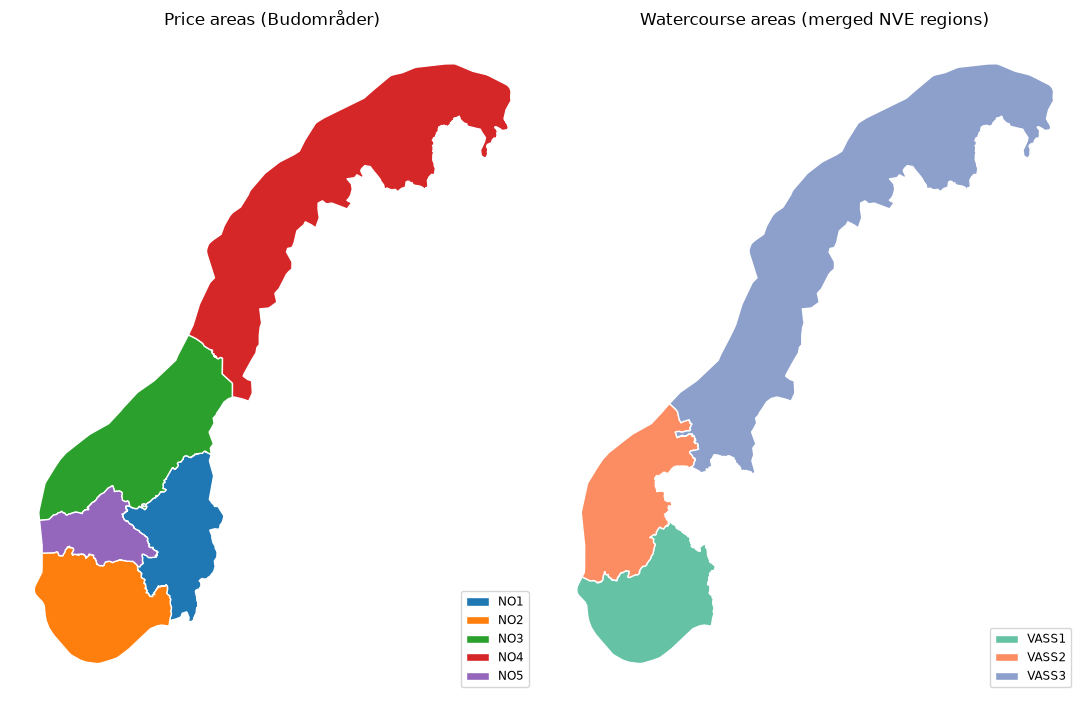

In [4]:
# The two sets of regions side by side. They do not line up: the price areas
# follow the power grid, the NVE regions follow the water.
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 7))

price_areas.plot(ax=left, column="area", edgecolor="white", cmap="tab10", legend=True,
                 legend_kwds={"fontsize": "small", "loc": "lower right"})
left.set_title("Price areas (Budområder)")

vass_areas.plot(ax=right, column="area", edgecolor="white", cmap="Set2", legend=True,
                legend_kwds={"fontsize": "small", "loc": "lower right"})
right.set_title("Watercourse areas (merged NVE regions)")

for axis in (left, right):
    axis.set_axis_off()

fig.tight_layout()
plt.show()

## 1.2 A thousand points in each region

To ask for the weather *in* a region you have to ask for the weather at points inside it. A thousand random points per region gives an even spread without having to think about where the interesting bits are.

The points are drawn in the metric projection rather than in degrees. Lines of longitude converge towards the pole, so uniform sampling in degrees would pack the northern points closer together and quietly weight the north too heavily.

In [5]:
sampled = regions.sample_points(price_areas, n=1000)

print(f"{len(sampled):,} points".replace(",", " "))
sampled.groupby("area").size().rename("points").to_frame()

5 000 points


,points
area,
NO1,1000
NO2,1000
NO3,1000
NO4,1000
NO5,1000


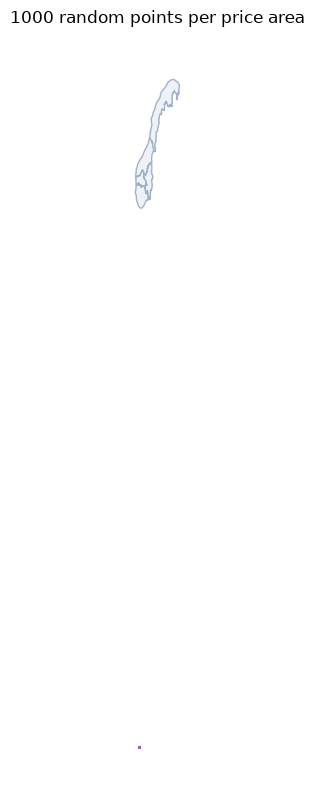

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 8))
price_areas.plot(ax=ax, color="#eef2f7", edgecolor="#9fb3c8")
sampled.plot(ax=ax, column="area", markersize=0.6, cmap="tab10", alpha=0.6)
ax.set_title("1000 random points per price area")
ax.set_axis_off()
fig.tight_layout()
plt.show()

## 1.3 The same answer from a third of the download

ERA5 is a grid with roughly 0.25 degree spacing, around 25 km. A thousand random points inside one region therefore land in far fewer distinct cells than a thousand — asking for the same cell repeatedly returns the same numbers and burns the request quota for nothing.

Rounding each point to its grid cell and keeping a count of how many points fell there gives the weights for the average. The weighted mean over the cells equals the plain mean over all thousand points, because a cell covering more of the region simply collected more of them.

In [7]:
grid = regions.to_era5_grid(sampled)

summary = grid.groupby("area")["weight"].agg(cells="count", points="sum")
summary["saved"] = (1 - summary["cells"] / summary["points"]).map("{:.0%}".format)
summary

,cells,points,saved
area,,,
NO1,182,1000,82%
NO2,195,1000,80%
NO3,311,1000,69%
NO4,564,1000,44%
NO5,109,1000,89%


---

# 2. Weather from Open-Meteo

ERA5 is a reanalysis: a weather model run over the past and corrected against whatever was actually observed. That is what makes it possible to ask for the temperature at an arbitrary coordinate in 2024, where no thermometer ever stood.

No key is needed. The limits that bite are on size, and they were worth testing before writing any code:

| Request | Result |
| --- | --- |
| 50 coordinates, one year | fine, 8 s, 12 MB |
| 100 coordinates, one year | fine, 27 s, 25 MB |
| 200 coordinates, one year | `429` — the per-minute quota counts volume, not calls |
| 500 coordinates, one year | `414 Request-URI Too Large` — the coordinates go in the URL |

So the download goes in batches of 60 with a pause between them.

In [8]:
# The function the task asks for: a region and a time interval in, hourly
# weather out. It looks up the sampled points for that region, reduces them to
# ERA5 grid cells, and downloads in batches.
def download_region(area: str, start: str, end: str, n_points: int = 1000) -> pd.DataFrame:
    """Hourly ERA5 weather for one region, averaged over the region."""
    one_area = price_areas[price_areas["area"] == area]
    if one_area.empty:
        raise ValueError(f"unknown area {area!r}; expected one of {list(price_areas['area'])}")

    points = regions.sample_points(one_area, n=n_points)
    cells = regions.to_era5_grid(points)
    print(f"{area}: {n_points} points -> {len(cells)} grid cells")

    hourly = weather.fetch(cells, start, end,
                           progress=lambda i, n: print(f"  batch {i}/{n}", flush=True))
    return hourly

In [9]:
# Reuse the download if it is already on disk; a year for NO3 takes a few
# minutes and there is no reason to ask for it twice.
CACHE = PROJECT_ROOT / "data" / "no3_2024_hourly.parquet"

if CACHE.exists():
    hourly = pd.read_parquet(CACHE)
    print(f"read from cache: {len(hourly):,} rows".replace(",", " "))
else:
    hourly = download_region("NO3", "2024-01-01", "2024-12-31")
    hourly.to_parquet(CACHE, index=False)

hourly.head()

read from cache: 2 652 768 rows


,time,temperature_2m,precipitation,lat,lon,weight
0,2024-01-01 00:00:00,6.1,0.0,61.0,4.25,1
1,2024-01-01 01:00:00,6.3,0.0,61.0,4.25,1
2,2024-01-01 02:00:00,6.0,0.0,61.0,4.25,1
3,2024-01-01 03:00:00,5.4,0.0,61.0,4.25,1
4,2024-01-01 04:00:00,5.1,0.0,61.0,4.25,1


In [10]:
no3 = weather.regional_average(hourly).set_index("time")

print(f"{len(no3)} hours, {no3.index.min():%d %b %Y} to {no3.index.max():%d %b %Y}")
print(f"temperature {no3['temperature_2m'].min():.1f} to {no3['temperature_2m'].max():.1f} °C")
print(f"precipitation {no3['precipitation'].sum():.0f} mm over the year")
no3.describe()

8784 hours, 01 Jan 2024 to 31 Dec 2024
temperature -13.7 to 22.2 °C
precipitation 1878 mm over the year


,temperature_2m,precipitation
count,8784.000000,8784.000000
mean,4.947370,0.213799
std,6.862679,0.285765
min,-13.744100,0.000000
25%,0.192975,0.016300
50%,4.824100,0.107050
75%,10.494400,0.305425
max,22.208000,3.035500


Hourly precipitation is mostly zeros with occasional spikes, which is hard to read and hard to do statistics on. Daily totals are the natural unit for rainfall, and daily means for temperature, so both are resampled before the analysis.

In [11]:
daily = pd.DataFrame({
    "precipitation": no3["precipitation"].resample("D").sum(),
    "temperature": no3["temperature_2m"].resample("D").mean(),
})
print(f"{len(daily)} days")
daily.head()

366 days


,precipitation,temperature
time,,
2024-01-01,0.2419,-6.393000
2024-01-02,0.2092,-9.788508
2024-01-03,0.0035,-12.520554
2024-01-04,0.1297,-12.493417
2024-01-05,0.9562,-9.467567


---

# 3. Outliers: precipitation and control limits

A year of weather is dominated by the seasons, so comparing a July day against the yearly average says nothing. The seasonal shape has to come out first.

The discrete cosine transform rewrites the series as a sum of cosines, slowest first. Keeping only the first few coefficients gives the seasonal shape; everything else is the fast variation the assignment calls SATV. Robust limits are placed around that, and then — this is the part that matters — the limits are transformed back by adding the seasonal shape again, so they become curves that follow the real measurements.

The assignment is explicit that the SATV values themselves are not plotted. They are only the route to the limits.

In [12]:
spc = quality.spc_outliers(daily["precipitation"], cutoff=8, sigmas=3.0)
spc["summary"]

{'cutoff': 8,
 'sigmas': 3.0,
 'n_outliers': 18,
 'share': 0.04918032786885246,
 'limit_width': 21.932141158350642,
 'largest': 24.75649289265734}

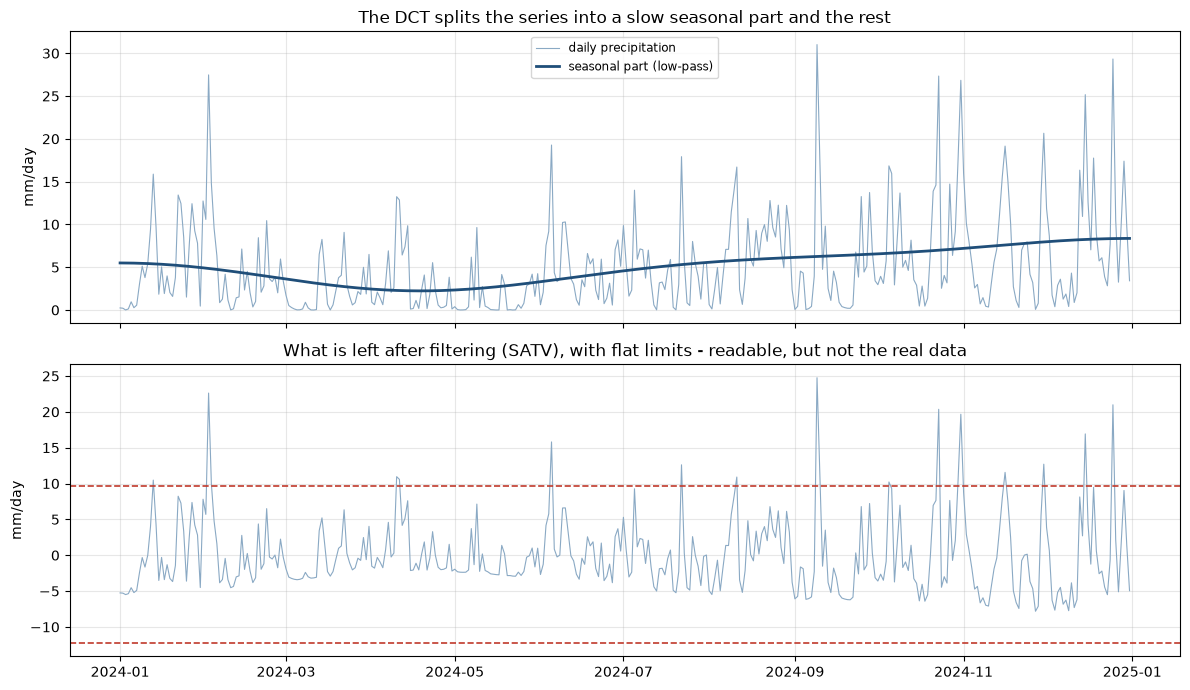

In [13]:
# Left: what the filtering does. Right: why the limits have to go back.
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

top.plot(daily.index, daily["precipitation"], linewidth=0.8, color="#8aa9c4", label="daily precipitation")
top.plot(spc["seasonal"].index, spc["seasonal"], linewidth=2, color="#1f4e79", label="seasonal part (low-pass)")
top.set_ylabel("mm/day")
top.set_title("The DCT splits the series into a slow seasonal part and the rest")
top.legend(fontsize="small")
top.grid(alpha=0.3)

bottom.plot(spc["satv"].index, spc["satv"], linewidth=0.8, color="#8aa9c4")
bottom.axhline(spc["satv"].median() + 3 * 1.4826 * np.median(np.abs(spc["satv"] - spc["satv"].median())),
               color="#c0392b", linestyle="--", linewidth=1.2)
bottom.axhline(spc["satv"].median() - 3 * 1.4826 * np.median(np.abs(spc["satv"] - spc["satv"].median())),
               color="#c0392b", linestyle="--", linewidth=1.2)
bottom.set_ylabel("mm/day")
bottom.set_title("What is left after filtering (SATV), with flat limits - readable, but not the real data")
bottom.grid(alpha=0.3)

fig.tight_layout()
plt.show()

And here is the plot the assignment actually asks for: the real measurements, with the limits bent back onto them.

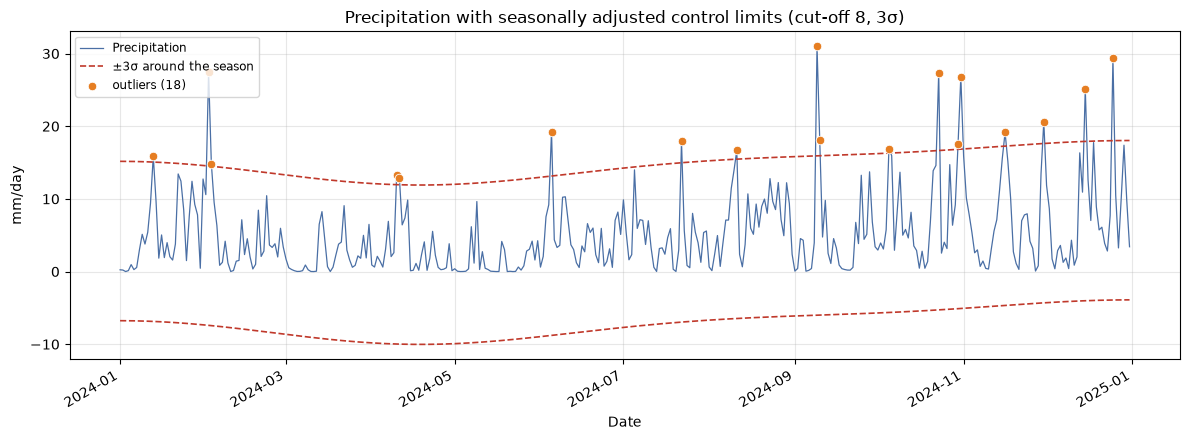

{'cutoff': 8,
 'sigmas': 3.0,
 'n_outliers': 18,
 'share': 0.04918032786885246,
 'limit_width': 21.932141158350642,
 'largest': 24.75649289265734}

In [14]:
def plot_spc(series, cutoff=8, sigmas=3.0, label="Precipitation", unit="mm/day"):
    """Plot a series with seasonally adjusted control limits and its outliers.

    Returns the figure and the summary, so the same function serves the
    notebook and the Streamlit page.
    """
    result = quality.spc_outliers(series, cutoff=cutoff, sigmas=sigmas)
    outliers = result["outliers"]

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(series.index, series, linewidth=0.9, color="#4a6fa5", label=label)
    ax.plot(result["upper"].index, result["upper"], color="#c0392b", linewidth=1.2,
            linestyle="--", label=f"±{sigmas:g}σ around the season")
    ax.plot(result["lower"].index, result["lower"], color="#c0392b", linewidth=1.2, linestyle="--")
    ax.scatter(series.index[outliers], series[outliers], s=38, color="#e67e22",
               zorder=5, edgecolor="white", linewidth=0.6,
               label=f"outliers ({int(outliers.sum())})")

    ax.set_ylabel(unit)
    ax.set_xlabel("Date")
    ax.set_title(f"{label} with seasonally adjusted control limits (cut-off {cutoff}, {sigmas:g}σ)")
    ax.legend(fontsize="small", loc="upper left")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()
    return fig, result["summary"]


figure, summary = plot_spc(daily["precipitation"])
plt.show()
summary

The limits are not straight. They rise through the wetter part of the year and fall back, which is exactly the point: a 20 mm day in October is ordinary, the same day in February is not.

## 3.1 Testing the function

The parameters have to do something, and the easiest way to show that they do is to vary them. A lower cut-off keeps less of the seasonal shape, and fewer sigmas narrows the limits.

In [15]:
for cutoff, sigmas in [(2, 3.0), (8, 3.0), (20, 3.0), (8, 2.0), (8, 4.0)]:
    s = quality.spc_outliers(daily["precipitation"], cutoff=cutoff, sigmas=sigmas)["summary"]
    print(f"cut-off {cutoff:>2}, {sigmas:.1f}σ -> {s['n_outliers']:>3} outliers "
          f"({s['share']:.1%}), limits {s['limit_width']:.1f} mm wide")

cut-off  2, 3.0σ ->  23 outliers (6.3%), limits 21.6 mm wide
cut-off  8, 3.0σ ->  18 outliers (4.9%), limits 21.9 mm wide
cut-off 20, 3.0σ ->  14 outliers (3.8%), limits 21.4 mm wide
cut-off  8, 2.0σ ->  46 outliers (12.6%), limits 14.6 mm wide
cut-off  8, 4.0σ ->   7 outliers (1.9%), limits 29.2 mm wide


In [16]:
# A harder test: plant five known spikes in a clean seasonal series and check
# that the function finds all of them.
rng = np.random.default_rng(0)
days = pd.date_range("2024-01-01", periods=366, freq="D")
season = 10 + 12 * np.sin(2 * np.pi * (np.arange(366) - 100) / 365)
synthetic = pd.Series(season + rng.normal(0, 1.5, 366), index=days)

planted = [40, 120, 200, 280, 340]
synthetic.iloc[planted] += [14, -13, 15, -14, 16]

found = set(np.flatnonzero(quality.spc_outliers(synthetic, cutoff=8, sigmas=3.0)["outliers"].to_numpy()))
print("planted:", planted)
print("found:  ", sorted(found))
print("all planted spikes recovered:", set(planted) <= found)

planted: [40, 120, 200, 280, 340]
found:   [np.int64(40), np.int64(120), np.int64(200), np.int64(219), np.int64(238), np.int64(270), np.int64(280), np.int64(303), np.int64(340)]
all planted spikes recovered: True


All five are found. The extra ones are the price of a three-sigma threshold on 366 noisy points, and tightening the threshold to four sigma removes them.

---

# 4. Anomalies: temperature and the Local Outlier Factor

The control limits above ask whether a point is far from where the season says it should be. The Local Outlier Factor asks something different: whether a point sits in a sparser neighbourhood than its neighbours do. That catches things that are unusual in context without being extreme overall.

Each day is described by two numbers, the temperature and the change from the day before. With only the temperature, LOF would reduce to picking out the hottest and coldest days — which the control limits already do. The change makes it flag abrupt swings as well.

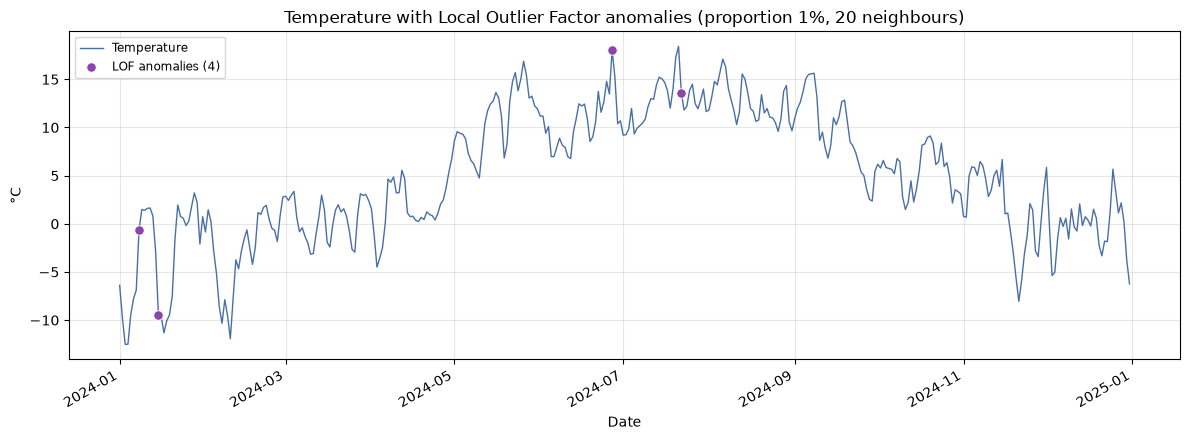

{'proportion': 0.01,
 'neighbours': 20,
 'n_anomalies': 4,
 'threshold': 1.9882604209167452,
 'max_score': 2.4078889682043956}

In [17]:
def plot_lof(series, proportion=0.01, neighbours=20, label="Temperature", unit="°C"):
    """Plot a series with its LOF anomalies marked."""
    result = quality.lof_anomalies(series, proportion=proportion, neighbours=neighbours)
    anomalies = result["anomalies"]

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(series.index, series, linewidth=1.0, color="#4a6fa5", label=label)
    ax.scatter(series.index[anomalies], series[anomalies], s=46, color="#8e44ad",
               zorder=5, edgecolor="white", linewidth=0.6,
               label=f"LOF anomalies ({int(anomalies.sum())})")

    ax.set_ylabel(unit)
    ax.set_xlabel("Date")
    ax.set_title(f"{label} with Local Outlier Factor anomalies "
                 f"(proportion {proportion:.0%}, {neighbours} neighbours)")
    ax.legend(fontsize="small", loc="upper left")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()
    return fig, result["summary"]


figure, summary = plot_lof(daily["temperature"])
plt.show()
summary

## 4.1 Testing the function

The proportion parameter should control how many days are flagged, more or less exactly.

In [18]:
for proportion in [0.005, 0.01, 0.02, 0.05]:
    s = quality.lof_anomalies(daily["temperature"], proportion=proportion)["summary"]
    expected = round(proportion * len(daily))
    print(f"proportion {proportion:>5.1%} -> {s['n_anomalies']:>3} anomalies "
          f"(expected about {expected})")

proportion  0.5% ->   2 anomalies (expected about 2)
proportion  1.0% ->   4 anomalies (expected about 4)
proportion  2.0% ->   8 anomalies (expected about 7)
proportion  5.0% ->  19 anomalies (expected about 18)


---

# 5. Seasonal-Trend decomposition of the reservoir filling

Back to the reservoir statistics from part 2, now read through the same API.

STL splits a series into a repeating seasonal shape, a slow trend and whatever is left. Unlike the DCT split above, STL lets the seasonal shape change gradually from year to year — which suits reservoirs, where the rhythm is the same every year but wet and dry years shift it around.

In [19]:
reservoirs = nve.fetch_reservoirs(first_year=2015)
filling = nve.one_area(reservoirs, "NO", 0)["fill_level"]
print(f"{len(filling)} weekly measurements, {filling.index.min():%b %Y} to {filling.index.max():%b %Y}")

617 weekly measurements, Jan 2015 to Oct 2026


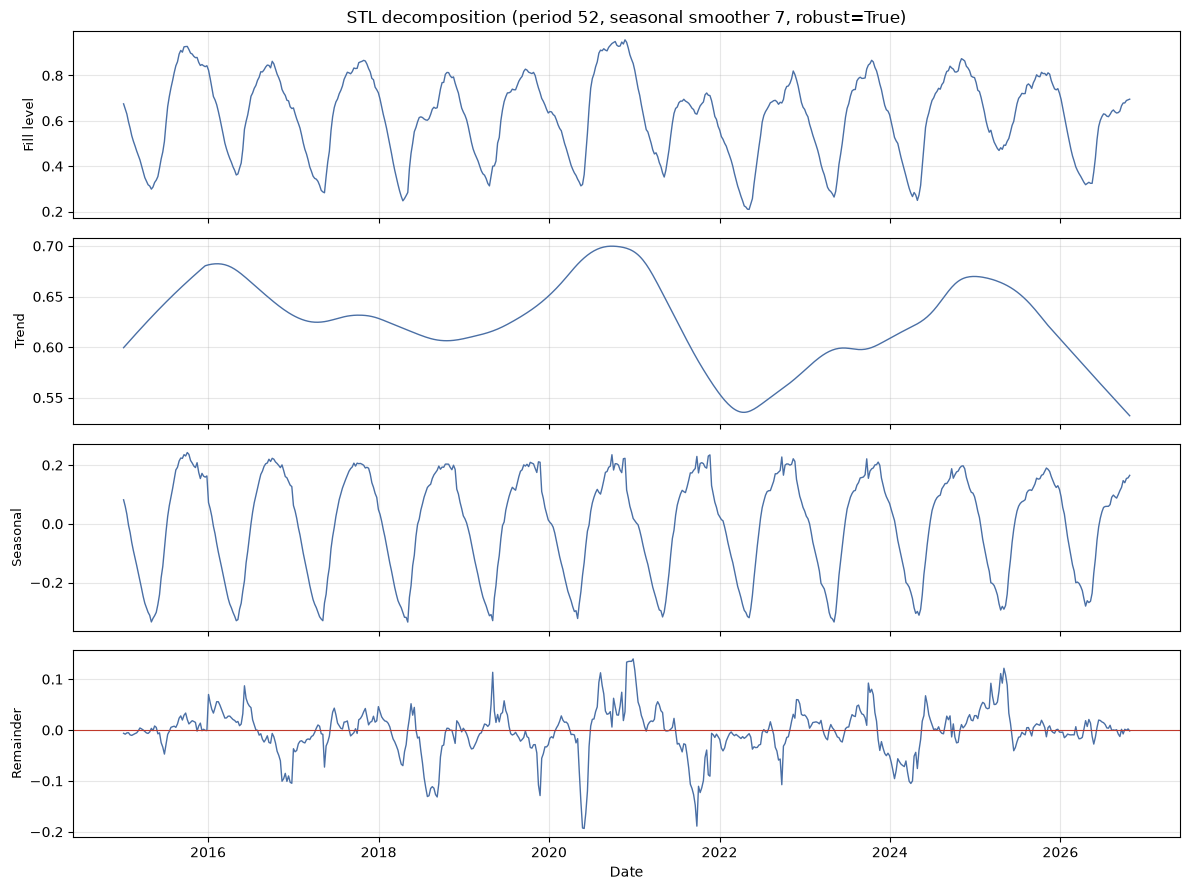

{'period': 52,
 'seasonal': 7,
 'robust': True,
 'seasonal_strength': 0.933,
 'resid_sd': 0.0455}

In [20]:
def plot_stl(series, period=52, seasonal=7, robust=True, label="Fill level"):
    """Run STL and plot the four panels."""
    result = quality.stl_decomposition(series, period=period, seasonal=seasonal, robust=robust)

    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    for axis, (values, name) in zip(axes, [
        (series, label), (result.trend, "Trend"),
        (result.seasonal, "Seasonal"), (result.resid, "Remainder"),
    ]):
        axis.plot(series.index, values, linewidth=1.0, color="#4a6fa5")
        axis.set_ylabel(name, fontsize=9)
        axis.grid(alpha=0.3)

    axes[3].axhline(0, color="#c0392b", linewidth=0.8)
    axes[0].set_title(f"STL decomposition (period {period}, seasonal smoother {seasonal}, "
                      f"robust={robust})")
    axes[3].set_xlabel("Date")
    fig.tight_layout()

    strength = 1 - result.resid.var() / (result.seasonal + result.resid).var()
    return fig, {"period": period, "seasonal": seasonal, "robust": robust,
                 "seasonal_strength": round(float(strength), 3),
                 "resid_sd": round(float(result.resid.std()), 4)}


figure, summary = plot_stl(filling)
plt.show()
summary

The seasonal panel is by far the largest component, which is what you would expect: the reservoirs fill through autumn and empty through winter, every year. The trend panel shows the slower drift between wet and dry years, and the remainder is small and mostly structureless — which is the sign of a decomposition that has captured what there was to capture.

## 5.1 Testing the function

In [21]:
for seasonal, robust in [(7, True), (7, False), (13, True), (25, True)]:
    _, s = plot_stl(filling, seasonal=seasonal, robust=robust)
    plt.close()
    print(f"seasonal {seasonal:>2}, robust={str(robust):<5} -> "
          f"seasonal strength {s['seasonal_strength']:.3f}, residual sd {s['resid_sd']:.4f}")

seasonal  7, robust=True  -> seasonal strength 0.933, residual sd 0.0455
seasonal  7, robust=False -> seasonal strength 0.955, residual sd 0.0369


seasonal 13, robust=True  -> seasonal strength 0.938, residual sd 0.0437
seasonal 25, robust=True  -> seasonal strength 0.939, residual sd 0.0430


---

# 6. Spectrogram

A single transform over the whole series says which rhythms are present, but not when. A spectrogram cuts the series into overlapping windows and transforms each one, so a rhythm that comes and goes shows up as a patch rather than being smeared over the whole picture.

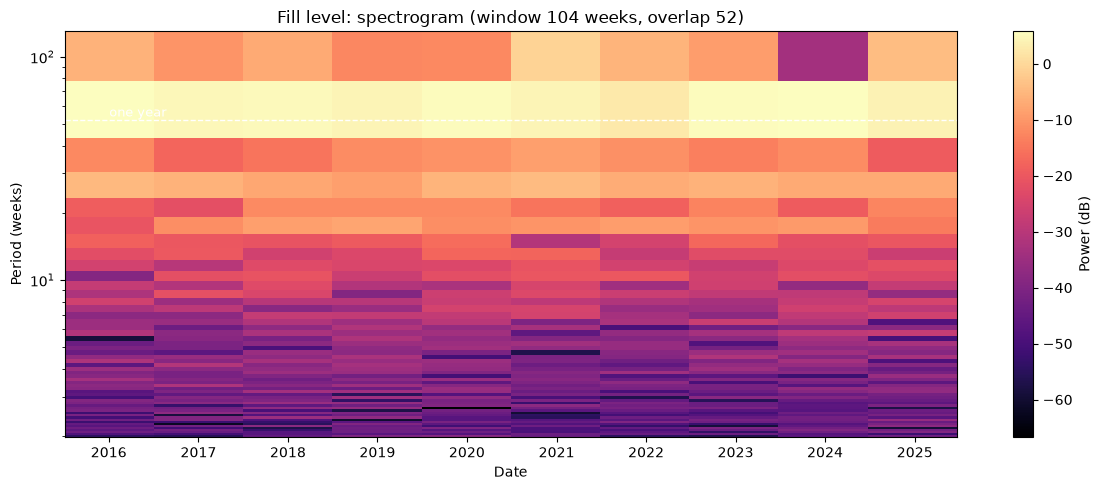

{'window': 104, 'overlap': 52, 'frequencies': 52, 'windows': 10}

In [22]:
def plot_spectrogram(series, window=104, overlap=None, label="Fill level"):
    """Plot how the frequency content of a series changes over time."""
    result = quality.spectrogram(series, window=window, overlap=overlap)

    # Weeks per cycle is easier to read than cycles per sample. The zero
    # frequency is dropped because it is the mean, not a rhythm.
    frequencies = result["frequencies"][1:]
    power = result["power"][1:]
    periods = 1 / frequencies

    start = series.index[0]
    times = [start + pd.Timedelta(weeks=t) for t in result["times"]]

    fig, ax = plt.subplots(figsize=(12, 5))
    mesh = ax.pcolormesh(times, periods, 10 * np.log10(power + 1e-12), shading="auto", cmap="magma")
    ax.set_yscale("log")
    ax.set_ylabel("Period (weeks)")
    ax.set_xlabel("Date")
    ax.set_title(f"{label}: spectrogram (window {result['window']} weeks, "
                 f"overlap {result['overlap']})")
    ax.axhline(52, color="white", linestyle="--", linewidth=1)
    ax.text(times[0], 54, "one year", color="white", fontsize=9)
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    fig.tight_layout()
    return fig, {"window": result["window"], "overlap": result["overlap"],
                 "frequencies": len(frequencies), "windows": len(result["times"])}


figure, summary = plot_spectrogram(filling)
plt.show()
summary

The bright band sits at the one-year line and stays bright across the whole picture, which says the yearly cycle is there all the time rather than appearing in some years only.

## 6.1 Testing the function

A longer window resolves frequency more finely but loses track of when things happen, and the number of windows falls accordingly.

In [23]:
for window, overlap in [(52, 26), (104, 52), (104, 90), (208, 104)]:
    _, s = plot_spectrogram(filling, window=window, overlap=overlap)
    plt.close()
    print(f"window {window:>3}, overlap {overlap:>3} -> "
          f"{s['frequencies']:>3} frequencies × {s['windows']:>2} time windows")

window  52, overlap  26 ->  26 frequencies × 22 time windows
window 104, overlap  52 ->  52 frequencies × 10 time windows
window 104, overlap  90 ->  52 frequencies × 37 time windows
window 208, overlap 104 -> 104 frequencies ×  4 time windows


---

# 7. Sources

**Data**

- [NVE Atlas](https://atlas.nve.no) — the two shapefiles, exported by hand from `Administrative områder → NVE_Region` and `Nettanlegg → Nettområder → Budområder`. There is no API for these layers.
- [NVE Magasinstatistikk API](https://biapi.nve.no/magasinstatistikk/swagger/index.html) — the reservoir filling, same source as part 2.
- [Open-Meteo](https://open-meteo.com/en/docs) — hourly ERA5 reanalysis. Free and no key required; the archive endpoint is `archive-api.open-meteo.com`.

**Methods**

- `scipy.fft.dct` / `idct` for the high-pass filter, and `scipy.signal.spectrogram`.
- `sklearn.neighbors.LocalOutlierFactor` for the anomalies.
- `statsmodels.tsa.seasonal.STL` for the decomposition.
- `geopandas` and `shapely` for reading the shapefiles and sampling inside the polygons.
- The median absolute deviation as a robust spread estimate, scaled by 1.4826 to match a standard deviation under normality. Course book, *Data quality* chapter.

**Tools**

- Claude (Claude Code) — see the AI usage section at the top.